# YOLO26：石头剪刀布目标检测

本实验采用 **Ultralytics YOLO26n**，使用 [melikeavan / Rock-Paper-Scissors v1](https://universe.roboflow.com/melikeavan/rock-paper-scissors-ishcs/dataset/1) 的正式 YOLO26 导出包。
训练 3,939 张、验证 338 张、测试 186 张；包内来源和版本已核对。逐类查看标注裁剪图确认类别映射：**0=paper（布）、1=rock（石头）、2=scissors（剪刀）**，不改变标注编号。

中英文课程共用这一份只读数据和已锁定的检测环境，训练产物写入各自 outputs 目录。首次在仓库根目录执行：

```powershell
.\english\02-object-detection\.venv\Scripts\python.exe .\english\scripts\fetch_rps.py --archive C:/Users/will/Downloads/Rock-Paper-Scissors.v1i.yolo26.zip --class-names paper rock scissors
.\start-notebooks.ps1 -Language zh-CN -Module detection
```

默认训练 10 轮；设置 `COURSE_EPOCHS=1` 是使用全部正式训练数据的一轮运行检查，包含独立测试评估。`COURSE_SMOKE=1` 则改用 COCO8，不代表本手势实验。
保留原始划分和标注，来源、压缩包哈希和实际计数见 provenance.json。旧 PaddleYOLO 教程仅供历史对照。

数据集 VOC / COCO / YOLO 转换与小土堆查看器使用说明见独立的[数据集格式专题](../../04-dataset-formats/README.zh-CN.md)。


In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", '1-epoch pipeline check via COURSE_EPOCHS')

Python: 3.12.12
torch: 2.14.1
Run mode: 1-epoch pipeline check via COURSE_EPOCHS


In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None:
    COURSE = next((p / "english" for p in [start, *start.parents]
                   if (p / "english" / "COURSE_ROOT").is_file()), None)
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'E:\\deep-learning-lab\\english\\data\\torch-cache'

In [3]:
import json
MODULE = COURSE / "02-object-detection"
OUTPUT = COURSE.parent / "02-object-detection" / "outputs"
# Keep Ultralytics settings local to this edition, before importing the package.
os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT / "ultralytics-config")
import torch
from ultralytics import YOLO, settings
import ultralytics
from ultralytics.utils import set_logging
import matplotlib.pyplot as plt
from detection_data import prepare_rps, RPS_DIRECTORY, RPS_SOURCE

OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
settings.update({"datasets_dir": str(MODULE / "data"),
                 "weights_dir": str(OUTPUT / "weights"),
                 "runs_dir": str(OUTPUT / "runs")})
# Ultralytics redraws a per-iteration progress bar; inside a saved notebook every redraw
# becomes a stored output record, so raise its log level and read the curve from results.png.
set_logging(verbose=False)
torch.set_num_threads(4)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Ultralytics version:", ultralytics.__version__)
print("Device:", DEVICE)

Ultralytics version: 8.4.177
Device: cpu


## 1. 核对数据与类别映射

YOLO 每行标注为 `class_id x_center y_center width height`，坐标按图片宽高归一化。校验器保留原始编号顺序，要求训练、验证、测试互相独立，并检查标注完整性、来源和跨集合完全重复图片。


In [4]:
if SMOKE:
    from detection_data import prepare_coco8
    DATA_CONFIG = str(prepare_coco8(MODULE / "data", OUTPUT / "coco8-smoke.yaml"))
    print("SMOKE TEST ONLY: COCO8 pipeline check; not hand-gesture training.")
else:
    DATA_CONFIG = OUTPUT / "rps-data.yaml"
    config, counts = prepare_rps(MODULE / "data" / RPS_DIRECTORY, DATA_CONFIG)
    print("English class mapping:", dict(enumerate(config["names"])))
    print("Validated split sizes:", counts)
    DATA_CONFIG = str(DATA_CONFIG)

English class mapping: {0: 'paper', 1: 'rock', 2: 'scissors'}
Validated split sizes: {'train': {'images': 3939, 'boxes': 4610}, 'val': {'images': 338, 'boxes': 400}, 'test': {'images': 186, 'boxes': 204}}


## 2. 加载预训练权重并微调

使用 `yolo26n.pt`。首次运行需要下载权重。Windows Notebook 使用 `workers=0`；课堂默认 320 像素、10 轮训练，CPU 实跑检查可用 `COURSE_EPOCHS=1`。训练结束后展示真实损失与 mAP 曲线。


Epochs: 1; image size: 320; smoke: False


Saved checkpoint: best.pt


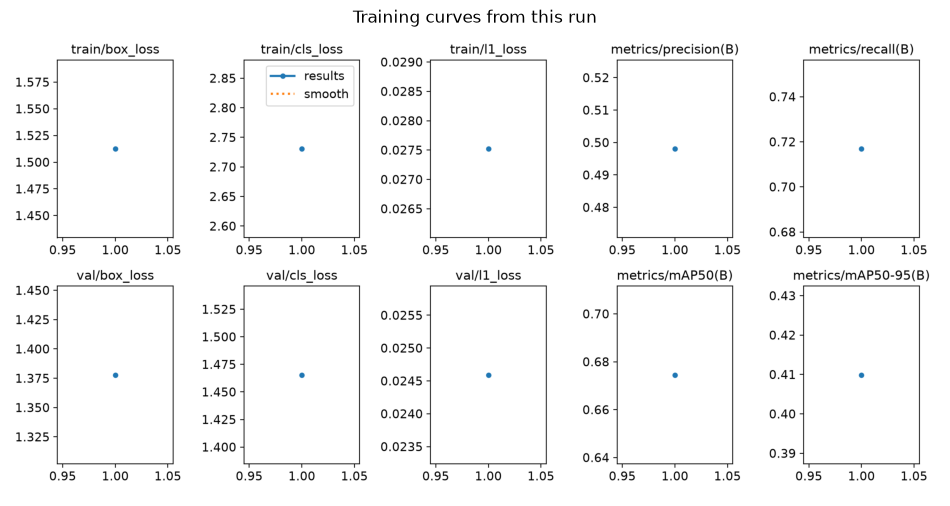

In [5]:
weights = MODULE / "outputs" / "weights" / "yolo26n.pt"
weights.parent.mkdir(parents=True, exist_ok=True)
model = YOLO(str(weights))
# Defaults are teaching parameters; runtime depends on the current dataset and hardware.
# COURSE_EPOCHS shortens a pipeline check; the classroom default stays at ten epochs.
EPOCHS = int(os.environ.get("COURSE_EPOCHS", 1 if SMOKE else 10))
IMGSZ = 64 if SMOKE else 320
print(f"Epochs: {EPOCHS}; image size: {IMGSZ}; smoke: {SMOKE}")
# verbose=False keeps the saved notebook readable: the per-iteration progress bar added
# about two thousand output records to the training cell without adding teaching value.
results = model.train(data=DATA_CONFIG, epochs=EPOCHS, imgsz=IMGSZ,
                      batch=2 if SMOKE else 8, workers=0, device=DEVICE,
                      seed=42, deterministic=True, verbose=False,
                      project=str(OUTPUT / "runs"),
                      name="coco8-smoke" if SMOKE else "rps-ishcs-v1-yolo26n",
                      exist_ok=False, plots=True, cache=False)
best = Path(model.trainer.best)
if not best.exists():
    raise RuntimeError("Training did not produce a best checkpoint.")
print("Saved checkpoint:", best.name)

# Show the curves this run wrote into its own folder before reading the metrics table.
curves = Path(model.trainer.save_dir) / "results.png"
if curves.exists():
    figure, axis = plt.subplots(figsize=(12, 8))
    axis.imshow(plt.imread(curves))
    axis.axis("off")
    axis.set_title("Training curves from this run")
    plt.show()
else:
    print("Expected plot not found:", curves)


## 3. 评估训练所得权重

用验证集选择设置，最终使用独立测试集评估；不能把训练集分数当作泛化效果。mAP50 与 mAP50-95 使用不同 IoU 阈值。COCO8 快速检查仅评估验证集。


test mAP50: 0.7266
test mAP50-95: 0.4535


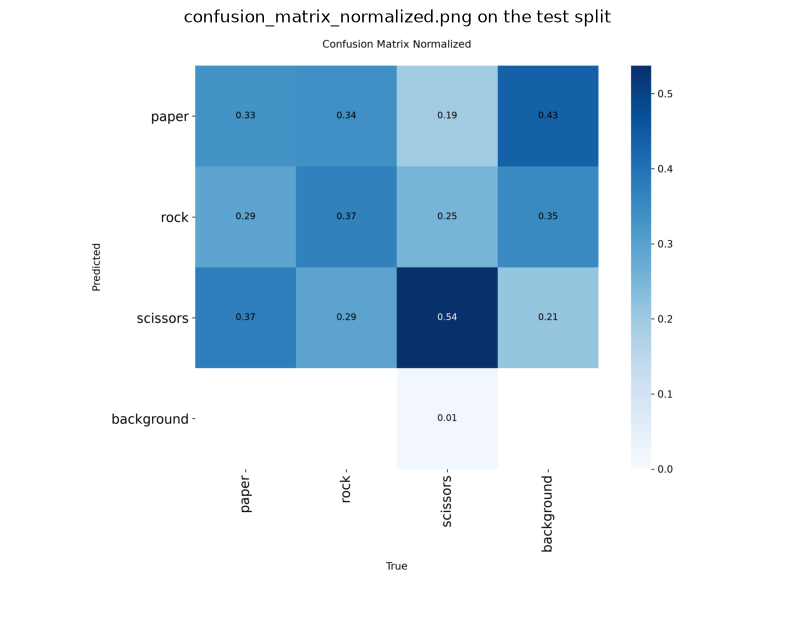

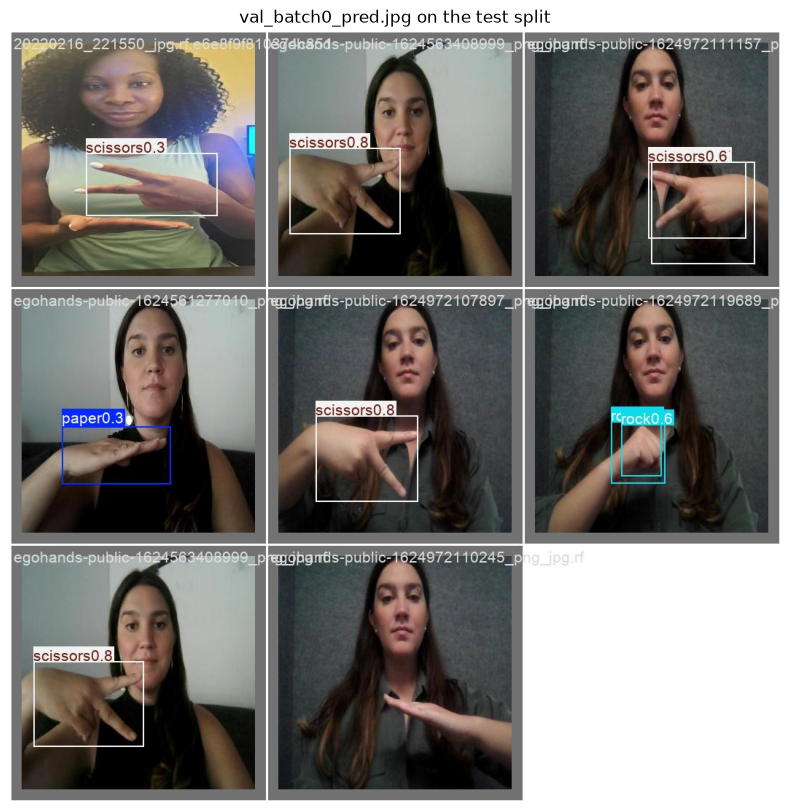

In [6]:
trained = YOLO(str(best))
split = "val" if SMOKE else "test"
metrics = trained.val(data=DATA_CONFIG, split=split, device=DEVICE,
                      imgsz=IMGSZ, workers=0, batch=2 if SMOKE else 8,
                      project=str(OUTPUT / "runs"), name="evaluation")
print(f"{split} mAP50: {metrics.box.map50:.4f}")
print(f"{split} mAP50-95: {metrics.box.map:.4f}")
report = {"smoke_test": SMOKE, "evaluation_split": split,
          "dataset": "COCO8" if SMOKE else RPS_DIRECTORY,
          "dataset_provenance": {} if SMOKE else json.loads((MODULE / "data" / RPS_DIRECTORY / "provenance.json").read_text(encoding="utf-8")),
          "map50": float(metrics.box.map50), "map50_95": float(metrics.box.map),
          "ultralytics_version": ultralytics.__version__}
(OUTPUT / ("smoke-metrics.json" if SMOKE else "rps-metrics.json")).write_text(
    json.dumps(report, indent=2), encoding="utf-8")

# The evaluation folder explains those numbers: a normalized confusion matrix and validation
# crops with the predicted boxes drawn.
for name in ("confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    figure_path = Path(metrics.save_dir) / name
    if figure_path.exists():
        figure, axis = plt.subplots(figsize=(10, 10))
        axis.imshow(plt.imread(figure_path))
        axis.axis("off")
        axis.set_title(f"{name} on the {split} split")
        plt.show()
    else:
        print("Expected plot not found:", figure_path)

## 4. 可视化预测（保留英文类别名）


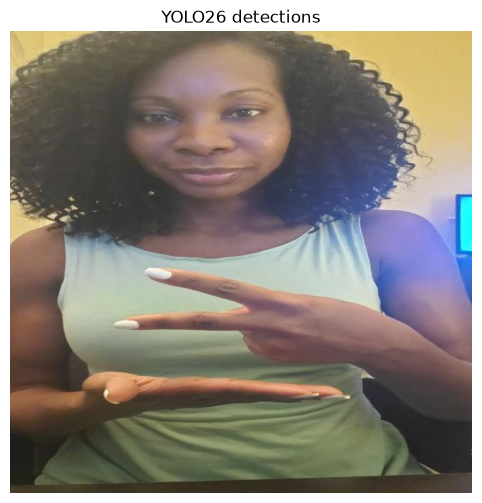

In [7]:
if SMOKE:
    from ultralytics.utils import ASSETS
    sample = ASSETS / "bus.jpg"
else:
    directory = MODULE / "data" / RPS_DIRECTORY / "test" / "images"
    sample = next(p for p in directory.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
prediction = trained.predict(source=str(sample), conf=0.25, device=DEVICE,
                              imgsz=IMGSZ, verbose=False)[0]
for box in prediction.boxes:
    print(f"Class: {prediction.names[int(box.cls.item())]}; confidence: {float(box.conf.item()):.3f}")
plt.figure(figsize=(8, 6))
plt.imshow(prediction.plot()[:, :, ::-1])
plt.title("YOLO26 detections" if not SMOKE else "COCO8 diagnostic predictions")
plt.axis("off")
plt.show()

## 练习与导出

检查漏检、误检和置信度阈值；比较模型时保持相同数据划分。格式转换不属于训练过程，见独立专题。可选 ONNX 导出命令为 `trained.export(format="onnx")`，应另行检查依赖与数值一致性。

来源：[YOLO26 文档](https://docs.ultralytics.com/models/yolo26/)、[数据集 v1](https://universe.roboflow.com/melikeavan/rock-paper-scissors-ishcs/dataset/1)。
